# Notebook 04 — Cohorts & Retention

> **SYNTHETIC DATA NOTICE:** All data is computer-generated. Findings describe only this simulated dataset.

**Business questions answered:**
- **Q4 (deeper):** Are new customers more likely to churn than existing ones?
- **Cohort retention heatmap** — which signup cohorts retain best?

**Evidence source:** `sql/04_cohort_retention_Q3_Q4.sql` + `sql/06_channel_and_tenure.sql`

In [1]:
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style='whitegrid')
plt.rcParams['figure.dpi'] = 120
FIGURES_DIR = Path('../outputs/figures')
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

conn = sqlite3.connect('../db/churn.db')
print('Connected.')

Connected.


## 1. Cohort Retention Table

In [2]:
df_cohort = pd.read_sql('SELECT * FROM cohort_retention ORDER BY cohort_month', conn)
df_cohort['cohort_month'] = pd.to_datetime(df_cohort['cohort_month'])
print(df_cohort[['cohort_month','cohort_size','retention_pct_m1','retention_pct_m6','retention_pct_m12']].to_string(index=False))

cohort_month  cohort_size  retention_pct_m1  retention_pct_m6  retention_pct_m12
  2024-01-01         1365             96.12             66.23              45.64
  2024-02-01         1253             96.81             67.12              46.13
  2024-03-01         1332             95.87             69.37              48.80
  2024-04-01         1286             96.73             68.66              48.21
  2024-05-01         1318             95.60             69.27              48.33
  2024-06-01         1247             96.15             68.08              49.80
  2024-07-01         1316             96.43             69.00              49.32
  2024-08-01         1294             96.06             68.24              46.83
  2024-09-01         1314             96.88             68.19              47.11
  2024-10-01         1331             96.02             66.34              46.96
  2024-11-01         1312             95.43             67.38              41.54
  2024-12-01         1298   

## 2. Cohort Retention Heatmap

Saved cohort retention heatmap.


<cell>:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


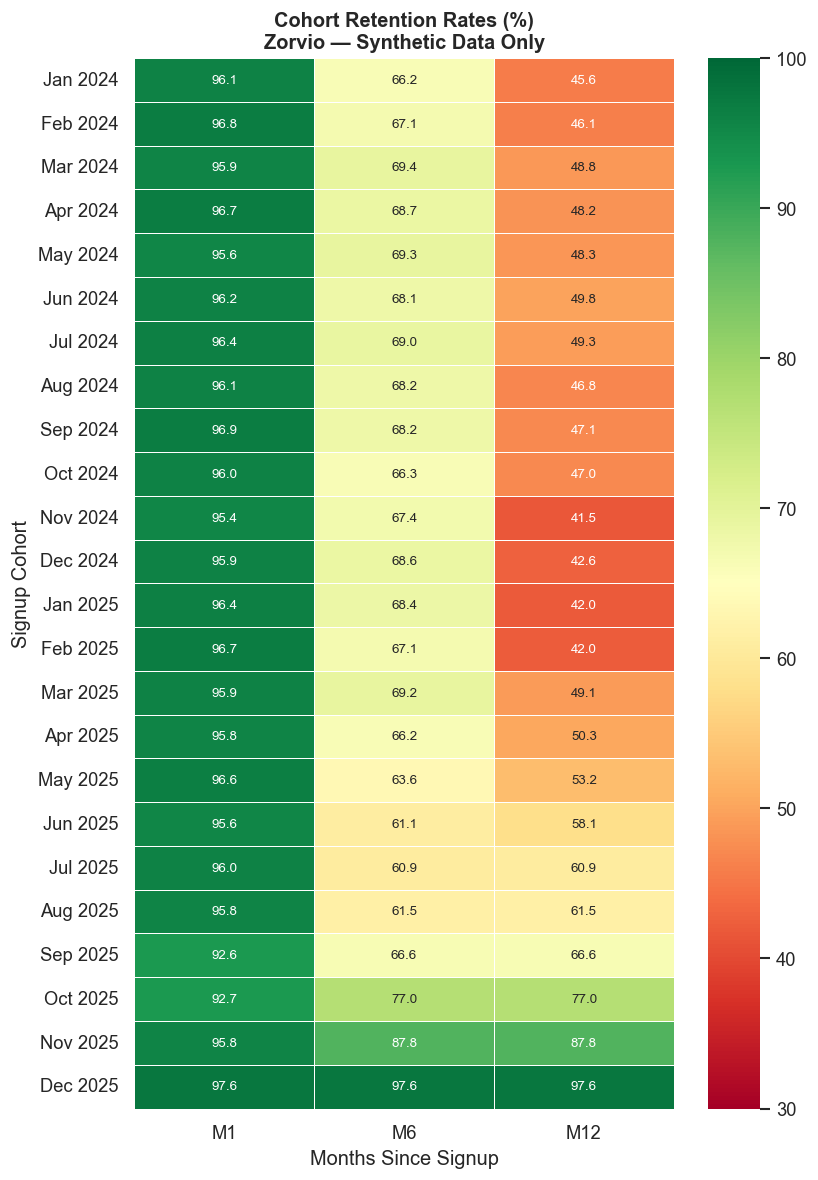

In [3]:
# Build heatmap matrix
heat_df = df_cohort.set_index(df_cohort['cohort_month'].dt.strftime('%b %Y'))[['retention_pct_m1','retention_pct_m6','retention_pct_m12']]
heat_df.columns = ['M1', 'M6', 'M12']

fig, ax = plt.subplots(figsize=(7, 10))
sns.heatmap(
    heat_df, annot=True, fmt='.1f', cmap='RdYlGn', vmin=30, vmax=100,
    linewidths=0.5, linecolor='white', ax=ax,
    annot_kws={'size': 8}
)
ax.set_title('Cohort Retention Rates (%)\nZorvio — Synthetic Data Only', fontsize=12, fontweight='bold')
ax.set_xlabel('Months Since Signup')
ax.set_ylabel('Signup Cohort')
plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_cohort_retention_heatmap.png', bbox_inches='tight')
plt.show()
print('Saved cohort retention heatmap.')

## 3. Tenure Bucket Analysis (Q4 — Early vs Established)

In [4]:
df_tenure = pd.read_sql('SELECT * FROM churn_by_tenure_bucket ORDER BY bucket_order', conn)
print(df_tenure.to_string(index=False))

tenure_bucket  bucket_order  total_customers  churned  churn_pct
   0-1 months             1             5571     4366      78.37
   2-3 months             2             5190     3289      63.37
   4-6 months             3             5710     3467      60.72
  7-12 months             4             7600     3960      52.11
   13+ months             5             5929     1898      32.01


<cell>:24: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


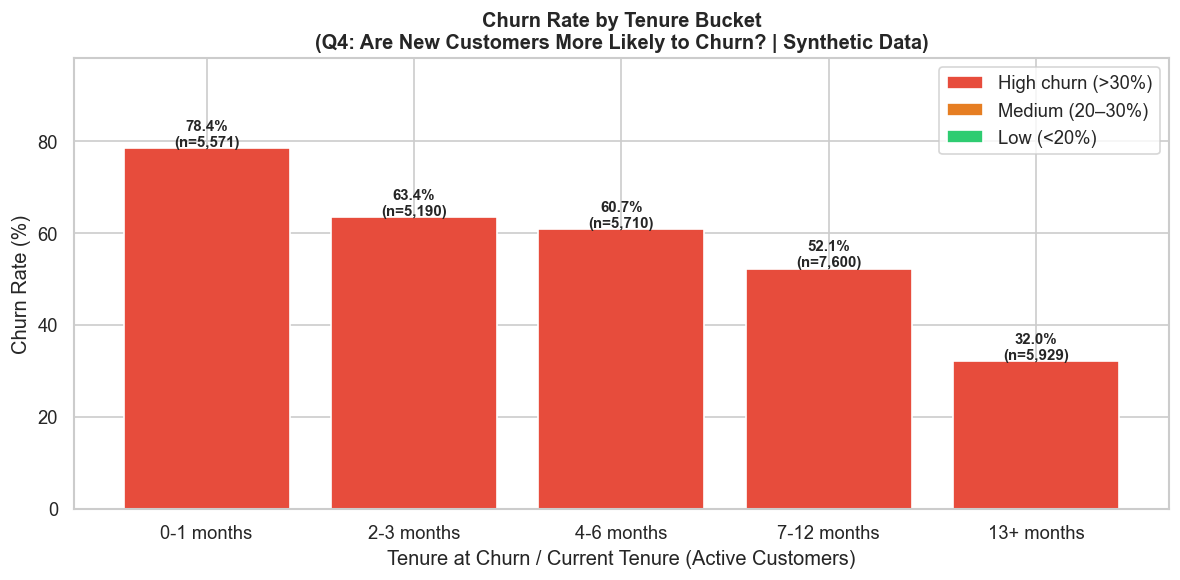

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#e74c3c' if c > 30 else '#e67e22' if c > 20 else '#2ecc71' for c in df_tenure['churn_pct']]
bars = ax.bar(df_tenure['tenure_bucket'], df_tenure['churn_pct'], color=colors, edgecolor='white')

for bar, val, n in zip(bars, df_tenure['churn_pct'], df_tenure['total_customers']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{val:.1f}%\n(n={n:,})', ha='center', fontsize=9, fontweight='bold')

ax.set_title('Churn Rate by Tenure Bucket\n(Q4: Are New Customers More Likely to Churn? | Synthetic Data)', fontsize=12, fontweight='bold')
ax.set_xlabel('Tenure at Churn / Current Tenure (Active Customers)')
ax.set_ylabel('Churn Rate (%)')
ax.set_ylim(0, df_tenure['churn_pct'].max() * 1.25)

from matplotlib.patches import Patch
legend_elements = [
    Patch(facecolor='#e74c3c', label='High churn (>30%)'),
    Patch(facecolor='#e67e22', label='Medium (20–30%)'),
    Patch(facecolor='#2ecc71', label='Low (<20%)')
]
ax.legend(handles=legend_elements, loc='upper right')

plt.tight_layout()
plt.savefig(FIGURES_DIR / '04_churn_by_tenure_bucket.png', bbox_inches='tight')
plt.show()

## 4. Average Tenure: Churned vs Active

In [6]:
df_avg = pd.read_sql('SELECT * FROM average_tenure', conn)
print(df_avg.to_string(index=False))
print()
print('INTERPRETATION:')
print('Churned users leave early on average (F004 finding).')
print('High early-period churn suggests onboarding or value-realization may be a friction point.')
print('CAVEAT: This is associational. Cannot determine cause without a controlled experiment.')

status_group  customer_count  avg_tenure_months  pct_churned_under_3_months
      Active           13020                9.8                        17.3
     Churned           16980                6.0                        36.2

INTERPRETATION:
Churned users leave early on average (F004 finding).
High early-period churn suggests onboarding or value-realization may be a friction point.
CAVEAT: This is associational. Cannot determine cause without a controlled experiment.


In [7]:
conn.close()